## Task - 1 Line Plot

In [159]:
pip install kagglehub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [160]:
import kagglehub

path = kagglehub.dataset_download("noopurbhatt/retail-sales-dataset",output_dir="G:/Gen-AI/Gen-AI-Assignments/GenAI-11-VenkataPrasannaReddy/retail_sales_data")

print("Path to dataset files:", path)

Path to dataset files: G:/Gen-AI/Gen-AI-Assignments/GenAI-11-VenkataPrasannaReddy/retail_sales_data


In [161]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [162]:

df_sales=pd.read_csv("./retail_sales_data/retail_sales_dataset.csv")
df_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   transaction_id      120000 non-null  str    
 1   transaction_date    120000 non-null  str    
 2   customer_id         120000 non-null  str    
 3   customer_gender     120000 non-null  str    
 4   customer_age_group  120000 non-null  str    
 5   customer_segment    120000 non-null  str    
 6   product_id          120000 non-null  str    
 7   product_name        120000 non-null  str    
 8   category            120000 non-null  str    
 9   brand               120000 non-null  str    
 10  quantity            120000 non-null  int64  
 11  unit_price          120000 non-null  float64
 12  discount_pct        120000 non-null  int64  
 13  sales_amount        120000 non-null  float64
 14  payment_method      120000 non-null  str    
 15  sales_channel       120000 non-null  str    


In [163]:
df_sales.sample(5)

,transaction_id,transaction_date,customer_id,customer_gender,customer_age_group,customer_segment,product_id,product_name,category,brand,quantity,unit_price,discount_pct,sales_amount,payment_method,sales_channel,region
84469,T0084470,2025-08-03,C021065,Female,18-24,Returning,P1088,Water Bottle,Sports,Brand 1,4,320.59,0,1282.36,Gift Card,Mobile App,North
73604,T0073605,2024-12-07,C023906,Female,18-24,Returning,P1035,Bread,Groceries,Brand 2,3,482.99,10,1304.07,PayPal,Mobile App,Central
5457,T0005458,2024-09-22,C024416,Female,35-44,VIP,P1011,Smartwatch,Electronics,Brand 2,2,15.19,25,22.79,Cash,In-Store,North
95685,T0095686,2024-05-11,C021712,Other,55+,Returning,P1112,Notebook,Books,Brand 1,2,84.80,0,169.60,Cash,Online,East
47949,T0047950,2024-10-01,C002430,Other,55+,VIP,P1042,Coffee,Groceries,Brand 3,1,250.11,0,250.11,PayPal,Mobile App,West


In [164]:
df_sales.quantity.max()

np.int64(5)

In [165]:
df_sales.transaction_date=pd.to_datetime(df_sales.transaction_date)
df_sales.customer_gender=df_sales.customer_gender.astype("category")
df_sales.customer_age_group=df_sales.customer_age_group.astype("category")
df_sales.customer_segment=df_sales.customer_segment.astype("category")
df_sales.category=df_sales.category.astype("category")
df_sales.brand=df_sales.brand.astype("category")
df_sales.payment_method=df_sales.payment_method.astype("category")
df_sales.sales_channel=df_sales.sales_channel.astype("category")
df_sales.region=df_sales.region.astype("category")
df_sales.discount_pct=df_sales.discount_pct.astype("int16")
df_sales.quantity=df_sales.quantity.astype("int16")


In [166]:
df_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   transaction_id      120000 non-null  str           
 1   transaction_date    120000 non-null  datetime64[us]
 2   customer_id         120000 non-null  str           
 3   customer_gender     120000 non-null  category      
 4   customer_age_group  120000 non-null  category      
 5   customer_segment    120000 non-null  category      
 6   product_id          120000 non-null  str           
 7   product_name        120000 non-null  str           
 8   category            120000 non-null  category      
 9   brand               120000 non-null  category      
 10  quantity            120000 non-null  int16         
 11  unit_price          120000 non-null  float64       
 12  discount_pct        120000 non-null  int16         
 13  sales_amount        120000 non-null  flo

In [167]:
df_sales.shape

(120000, 17)

In [168]:
# writing to parquet because we will perform operations on columns and also to preserve the datatypes modified
df_sales.to_parquet("retail_sales_data/retail_sales_dataset.parquet")

In [169]:
df_sales=pd.read_parquet("retail_sales_data/retail_sales_dataset.parquet")

In [170]:
df_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   transaction_id      120000 non-null  str           
 1   transaction_date    120000 non-null  datetime64[us]
 2   customer_id         120000 non-null  str           
 3   customer_gender     120000 non-null  category      
 4   customer_age_group  120000 non-null  category      
 5   customer_segment    120000 non-null  category      
 6   product_id          120000 non-null  str           
 7   product_name        120000 non-null  str           
 8   category            120000 non-null  category      
 9   brand               120000 non-null  category      
 10  quantity            120000 non-null  int16         
 11  unit_price          120000 non-null  float64       
 12  discount_pct        120000 non-null  int16         
 13  sales_amount        120000 non-null  flo

In [171]:
df_sales[df_sales.transaction_date.isna()]

,transaction_id,transaction_date,customer_id,customer_gender,customer_age_group,customer_segment,product_id,product_name,category,brand,quantity,unit_price,discount_pct,sales_amount,payment_method,sales_channel,region


In [172]:
df_sales["transaction_month"]=df_sales.transaction_date.dt.month_name()

In [173]:
df_sales.select(["transaction_date","transaction_month"])

,transaction_date,transaction_month
0,2024-04-24,April
1,2025-07-12,July
2,2025-06-01,June
3,2025-08-26,August
4,2024-12-10,December
...,...,...
119995,2025-05-17,May
119996,2025-11-16,November
119997,2025-07-18,July
119998,2025-07-27,July


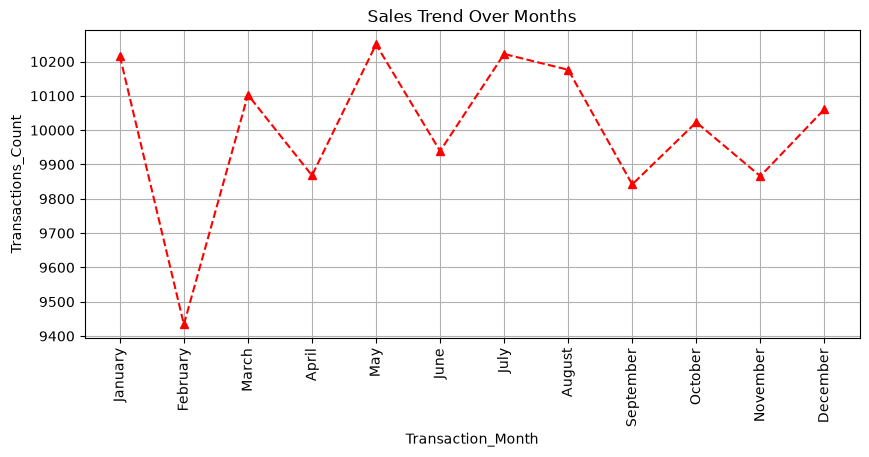

In [174]:
data=df_sales.groupby("transaction_month")["transaction_id"].count()
data.index=pd.CategoricalIndex(data.index,categories=["January","February","March","April","May","June","July","August","September","October","November","December"],ordered=True)
data=data.sort_index()
x=data.index
y=data.values
plt.figure(figsize=(10,4))
plt.xlabel("Transaction_Month")
plt.ylabel("Transactions_Count")
plt.title("Sales Trend Over Months")
plt.plot(x,y,color="red",marker="^",linewidth=1.5,linestyle="--")
plt.xticks(rotation="vertical")
plt.grid()
plt.show()

## Task - 2  Scatter Plot

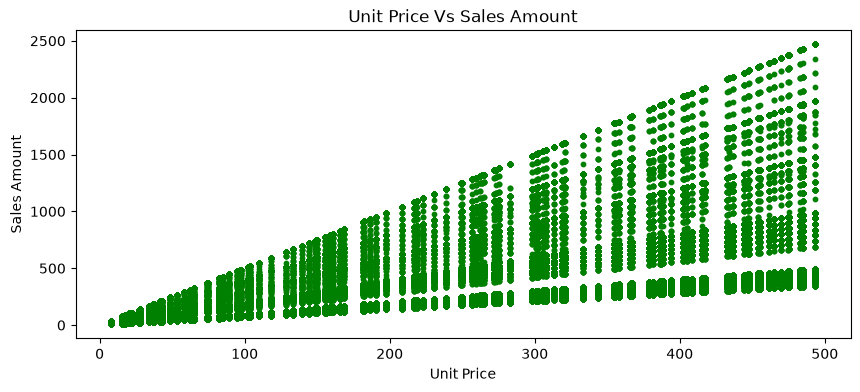

In [175]:
## Checking how unit_price is impacting sales_amount
x=df_sales.unit_price
y=df_sales.sales_amount
plt.figure(figsize=(10,4))
plt.xlabel("Unit Price")
plt.ylabel("Sales Amount")
plt.title("Unit Price Vs Sales Amount")
plt.scatter(x,y,10,color="green")
plt.show()

## Task - 3 Bar Plot

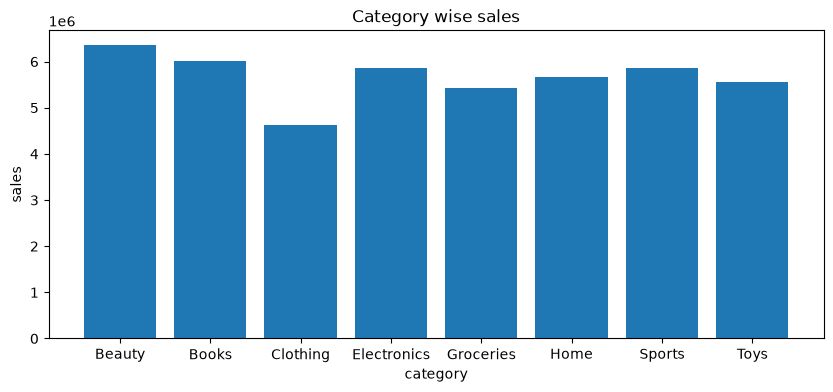

In [176]:
# Sales per category

data=df_sales.groupby("category")["sales_amount"].sum()
x=data.index
y=data.values
plt.figure(figsize=(10,4))
plt.xlabel("category")
plt.ylabel("sales")
plt.title("Category wise sales")
plt.bar(x,y)
plt.show()


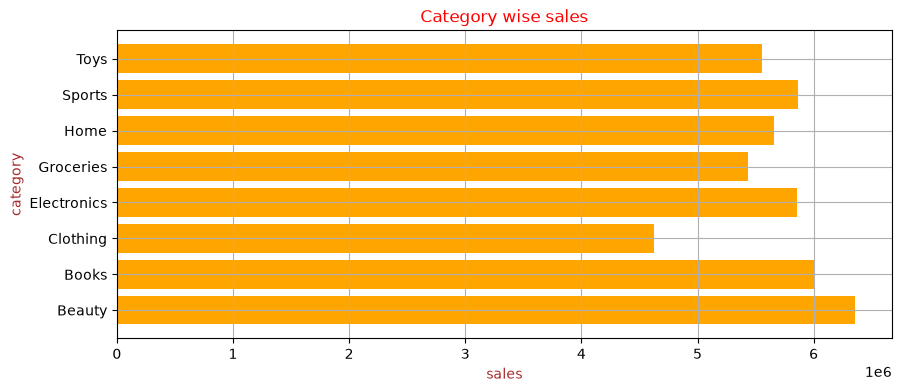

In [177]:
# Sales per category horizontal bar plot

data=df_sales.groupby("category")["sales_amount"].sum()
x=data.index
y=data.values
plt.figure(figsize=(10,4))
plt.xlabel("sales",color="brown")
plt.ylabel("category",color="brown")
plt.title("Category wise sales",color="red")
plt.barh(x,y,color="orange")
plt.grid()
plt.show()


## Task - 4 Multiple Bar Plot

In [178]:
df_sales["transaction_year"]=df_sales.transaction_date.dt.year
df_sales.sample(5)

,transaction_id,transaction_date,customer_id,customer_gender,customer_age_group,customer_segment,product_id,product_name,category,brand,quantity,unit_price,discount_pct,sales_amount,payment_method,sales_channel,region,transaction_month,transaction_year
88146,T0088147,2024-01-18,C009733,Female,18-24,VIP,P1066,Lamp,Home,Brand 3,4,273.63,0,1094.52,Gift Card,Mobile App,West,January,2024
50403,T0050404,2024-06-13,C008423,Male,45-54,New,P1045,Cereal,Groceries,Brand 3,1,133.10,5,126.44,Debit Card,In-Store,West,June,2024
14183,T0014184,2024-01-23,C000424,Other,45-54,Returning,P1052,Lipstick,Beauty,Brand 1,1,388.69,0,388.69,Credit Card,In-Store,Central,January,2024
59245,T0059246,2025-05-14,C009190,Female,35-44,New,P1097,Board Game,Toys,Brand 1,1,263.75,0,263.75,Cash,Mobile App,North,May,2025
75161,T0075162,2024-12-31,C004812,Female,25-34,New,P1003,Smartphone,Electronics,Brand 3,1,367.34,20,293.87,Debit Card,In-Store,West,December,2024


In [179]:
df_sales.transaction_year.value_counts()

transaction_year
2024    60102
2025    59898
Name: count, dtype: int64

In [180]:
sales_in_2024=df_sales.groupby(df_sales[df_sales.transaction_year==2024].transaction_month)["sales_amount"].sum()
sales_in_2025=df_sales.groupby(df_sales[df_sales.transaction_year==2025].transaction_month)["sales_amount"].sum()
sales_in_2024.index=pd.CategoricalIndex(sales_in_2024.index,categories=["January","February","March","April","May","June","July","August","September","October","November","December"],ordered=True)
sales_in_2024=sales_in_2024.sort_index()
sales_in_2025.index=pd.CategoricalIndex(sales_in_2025.index,categories=["January","February","March","April","May","June","July","August","September","October","November","December"],ordered=True)
sales_in_2025=sales_in_2025.sort_index()

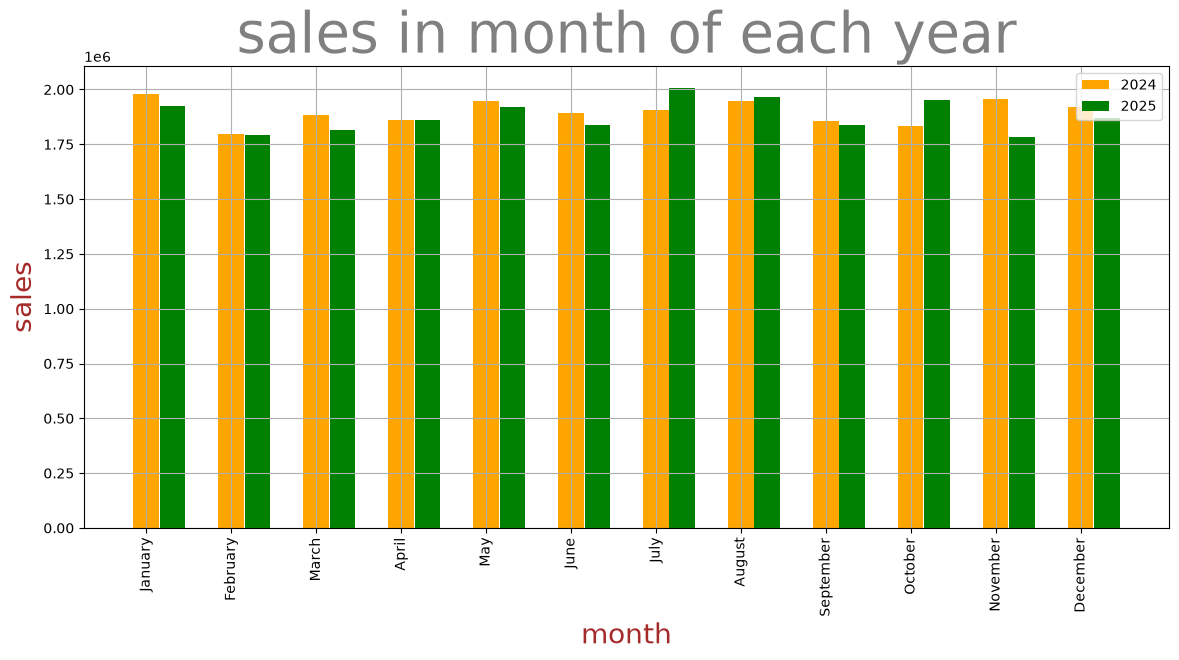

In [181]:
plt.figure(figsize=(14,6))
plt.xlabel("month",color="brown",size=20)
plt.ylabel("sales",color="brown",size=20)
plt.title("sales in month of each year",color="grey",size=40)
plt.bar(np.arange(12),sales_in_2024.values,color="orange",width=0.3,label=2024)
plt.bar(np.arange(12)+0.31,sales_in_2025.values,color="green",width=0.3,label=2025)
plt.grid()
plt.xticks(np.arange(12),["January","February","March","April","May","June","July","August","September","October","November","December"],rotation="vertical")
plt.legend()
plt.show()

## Task - 5 Stacked Bar Chart

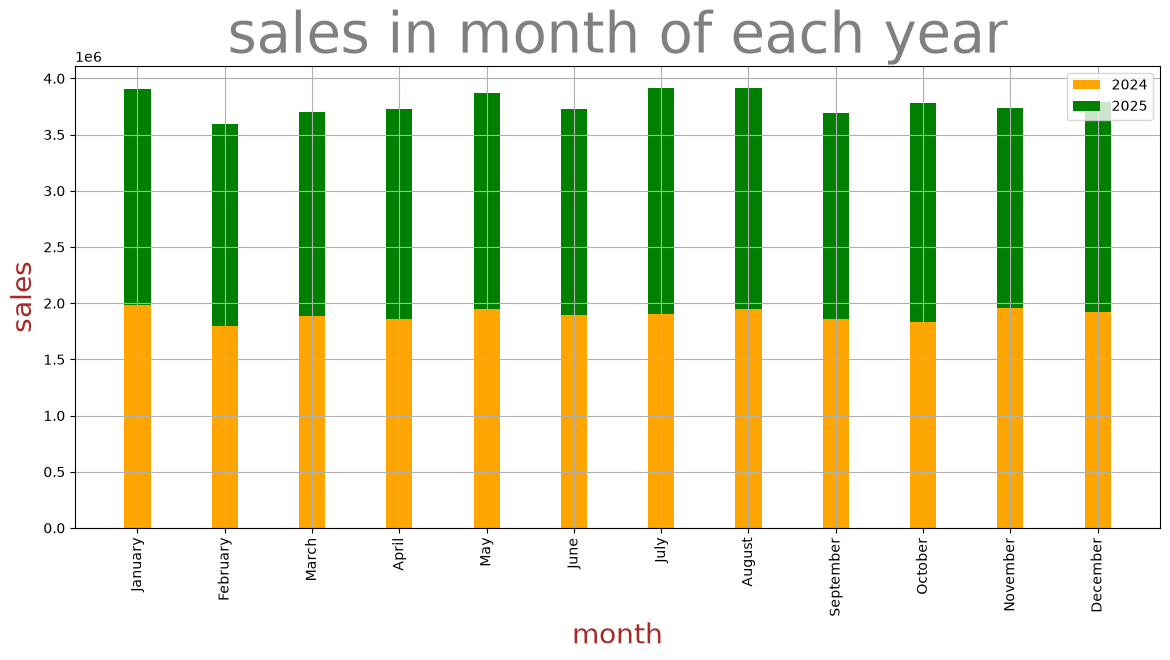

In [182]:
plt.figure(figsize=(14,6))
plt.xlabel("month",color="brown",size=20)
plt.ylabel("sales",color="brown",size=20)
plt.title("sales in month of each year",color="grey",size=40)
plt.bar(sales_in_2024.index,sales_in_2024.values,color="orange",width=0.3,label=2024)
plt.bar(sales_in_2025.index,sales_in_2025.values,color="green",width=0.3,label=2025,bottom=sales_in_2024.values)
plt.grid()
plt.xticks(np.arange(12),["January","February","March","April","May","June","July","August","September","October","November","December"],rotation="vertical")
plt.legend()
plt.show()

## Task - 6 Histogram

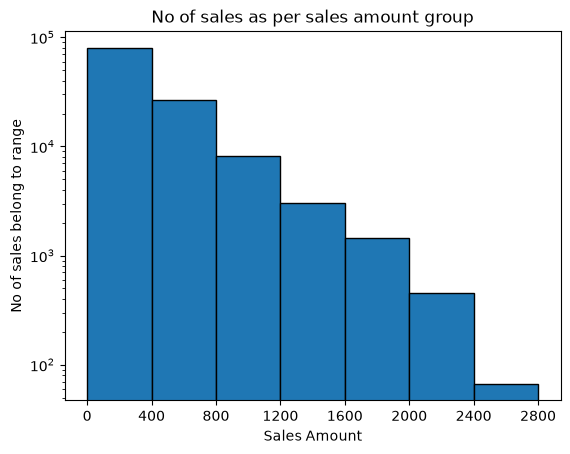

In [183]:
import importlib
import matplotlib.pyplot as plt
importlib.reload(plt)
bins = [0, 400, 800, 1200, 1600, 2000, 2400, 2800]
plt.xlabel("Sales Amount")
plt.ylabel("No of sales belong to range")
plt.title("No of sales as per sales amount group")
plt.hist(df_sales.sales_amount, bins=bins, log=True, edgecolor="black")
plt.xticks(bins)
plt.show()


## Task - 7 Pie Chart (Market Share)

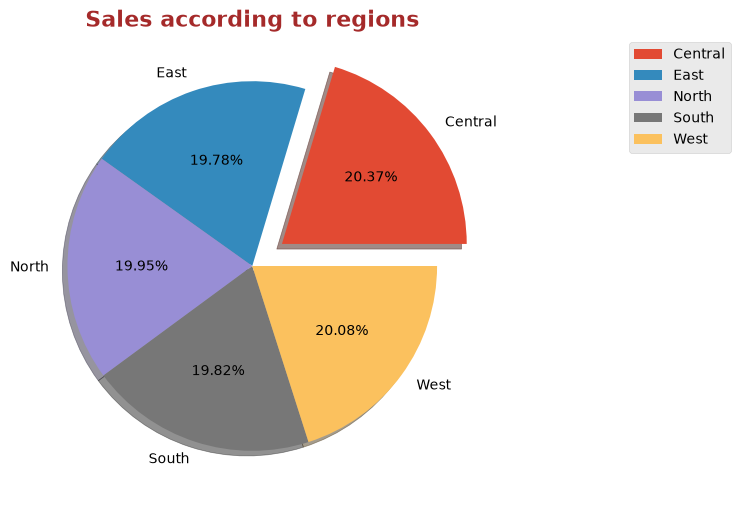

In [192]:
data=df_sales.groupby("region")["sales_amount"].sum()
plt.style.use("ggplot")
plt.figure(figsize=(12,6))
plt.pie(data.values,labels=data.index,autopct="%0.2f%%",explode=[0.2,0,0,0,0],shadow=True)
plt.title("Sales according to regions", fontsize=16, fontweight="bold",color="brown")
plt.legend(loc="upper left",bbox_to_anchor=(1.3,1))
plt.show()